In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor

# 1. Load RAW dataset (to prevent pre-split imputation leakage!)
df_raw = pd.read_csv("hku_cc_main_dataset_raw_na.csv")

feature_cols = [
    'is_online', 'is_comm_intensive',
    'study_load_total', 'hours_lectures', 'hours_tutorials',
    'hours_self_study', 'hours_assessment', 'weight_essay',
    'weight_quiz_exam', 'weight_presentation', 'weight_participation',
    'weight_project', 'quota_per_semester',
    'aoi_CCCH', 'aoi_CCGL', 'aoi_CCHU', 'aoi_CCST',
    'sem_both', 'sem_sem1', 'sem_sem2'
]
# Add SDG columns if present
sdg_cols = [c for c in df_raw.columns if c.startswith("sdg_")]
X_all = df_raw[feature_cols].copy()

targets = {
    "SIS Effectiveness": "sis_mean_effectiveness",
    "LLM Sentiment": "llm_sentiment_score",
    "LLM Perceived Workload": "llm_perceived_workload",
    "Sem-Adj Popularity Pct": "enrol_popularity_pct_sem_adj"
}

# ---------------------------------------------------------
# PART A: Leak-Free Multi-Target Cross-Validation Comparison
# ---------------------------------------------------------
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

results_list = []
trained_fallback_models = {}

for t_label, t_col in targets.items():
    valid_mask = df_raw[t_col].notna()
    X_val = X_all.loc[valid_mask]
    y_val = df_raw.loc[valid_mask, t_col].astype(float)

    models = {
        "Baseline (Mean)": make_pipeline(SimpleImputer(strategy="median"), DummyRegressor(strategy="mean")),
        "RidgeCV": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20), cv=5)),
        "LassoCV": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LassoCV(alphas=np.logspace(-2, 2, 20), cv=5, max_iter=10000)),
        "RandomForest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=6, random_state=42))
    }

    for m_name, pipe in models.items():
        scores = cross_validate(pipe, X_val, y_val, cv=cv, scoring=scoring)
        results_list.append({
            "Target Metric": t_label,
            "Valid N": len(y_val),
            "Model": m_name,
            "MAE": f"{-scores['test_mae'].mean():.3f} ± {scores['test_mae'].std():.3f}",
            "RMSE": f"{-scores['test_rmse'].mean():.3f} ± {scores['test_rmse'].std():.3f}",
            "R2_mean": scores['test_r2'].mean(),
            "R2": f"{scores['test_r2'].mean():.3f} ± {scores['test_r2'].std():.3f}"
        })
        if m_name == "RidgeCV":
            pipe.fit(X_val, y_val)
            trained_fallback_models[t_col] = pipe

df_cv_results = pd.DataFrame(results_list)
print("=== MULTI-TARGET MODEL EVALUATION TABLE (5x5 Repeated K-Fold CV) ===")
print(df_cv_results[["Target Metric", "Valid N", "Model", "MAE", "RMSE", "R2"]].to_string(index=False))
df_cv_results.to_csv("model_comparison_results.csv", index=False)

=== MULTI-TARGET MODEL EVALUATION TABLE (5x5 Repeated K-Fold CV) ===
         Target Metric  Valid N           Model           MAE          RMSE             R2
     SIS Effectiveness      268 Baseline (Mean) 5.194 ± 0.558 6.618 ± 0.672 -0.023 ± 0.032
     SIS Effectiveness      268         RidgeCV 4.908 ± 0.557 6.370 ± 0.641  0.051 ± 0.043
     SIS Effectiveness      268         LassoCV 4.975 ± 0.537 6.438 ± 0.621  0.030 ± 0.059
     SIS Effectiveness      268    RandomForest 5.010 ± 0.580 6.573 ± 0.627 -0.013 ± 0.081
         LLM Sentiment      248 Baseline (Mean) 0.522 ± 0.070 0.687 ± 0.084 -0.033 ± 0.051
         LLM Sentiment      248         RidgeCV 0.523 ± 0.069 0.690 ± 0.083 -0.043 ± 0.055
         LLM Sentiment      248         LassoCV 0.522 ± 0.070 0.688 ± 0.083 -0.036 ± 0.052
         LLM Sentiment      248    RandomForest 0.534 ± 0.073 0.708 ± 0.088 -0.097 ± 0.066
LLM Perceived Workload      248 Baseline (Mean) 0.522 ± 0.062 0.667 ± 0.086 -0.037 ± 0.039
LLM Perceived Workloa

In [4]:
# ---------------------------------------------------------
# PART B: Hybrid Cold-Start Imputation + Recommendation Engine (Active 2026-27 Courses Only)
# ---------------------------------------------------------
df_rec = df_raw.copy()

# 1. Cold-Start Fallback: Use trained RidgeCV models (from Part A) to predict missing target values
for t_col, model in trained_fallback_models.items():
    missing_mask = df_rec[t_col].isna()
    if missing_mask.sum() > 0:
        df_rec.loc[missing_mask, t_col] = model.predict(X_all.loc[missing_mask])

# 2. Filter to ONLY Active 2026-2027 courses (courses present on enrol_stat.html with valid quota)
df_active = df_rec[df_raw["quota_per_semester"].notna()].copy().reset_index(drop=True)
print(f"Total courses in dataset: {len(df_rec)} | Active 2026-27 courses for Recommendation: {len(df_active)}")

# 3. Normalize the 4 core utility dimensions into [0, 1] across active courses (1.0 = Best for student)
scaler_mm = MinMaxScaler()
df_active["norm_quality"] = scaler_mm.fit_transform(df_active[["sis_mean_effectiveness"]])
df_active["norm_sentiment"] = scaler_mm.fit_transform(df_active[["llm_sentiment_score"]])
# Invert workload so 1.0 = Lightest/Chillest workload!
df_active["norm_light_workload"] = 1.0 - scaler_mm.fit_transform(df_active[["llm_perceived_workload"]])
# Invert popularity percentile so 1.0 = Highest Registration Ease (most vacancies relative to semester)
df_active["norm_reg_ease"] = 1.0 - df_active["enrol_popularity_pct_sem_adj"]

def recommend_courses(
    df,
    w_quality=0.25,
    w_sentiment=0.25,
    w_light_workload=0.25,
    w_reg_ease=0.25,
    w_no_exam=0.0,
    w_no_group_proj=0.0,
    aoi_filter=None,
    sem_filter=None,
    top_k=5
):
    """
    Personalized Multi-Criteria Recommendation Engine for Active 2026-27 HKU Common Core Courses.
    """
    sub = df.copy()
    if aoi_filter:
        sub = sub[sub["aoi"] == aoi_filter]
    if sem_filter == "sem1":
        sub = sub[(sub["sem_sem1"] == 1) | (sub["sem_both"] == 1)]
    elif sem_filter == "sem2":
        sub = sub[(sub["sem_sem2"] == 1) | (sub["sem_both"] == 1)]

    # Assessment preference alignment (1.0 = 0% exam/project, 0.0 = 100% exam/project)
    no_exam_score = 1.0 - (sub["weight_quiz_exam"] / 100.0)
    no_proj_score = 1.0 - (sub["weight_project"] / 100.0)

    total_w = w_quality + w_sentiment + w_light_workload + w_reg_ease + w_no_exam + w_no_group_proj
    if total_w == 0:
        total_w = 1.0

    sub["rec_score"] = (
        w_quality * sub["norm_quality"] +
        w_sentiment * sub["norm_sentiment"] +
        w_light_workload * sub["norm_light_workload"] +
        w_reg_ease * sub["norm_reg_ease"] +
        w_no_exam * no_exam_score +
        w_no_group_proj * no_proj_score
    ) / total_w * 100.0

    cols_show = [
        "course_code", "course_name", "aoi", "rec_score",
        "sis_mean_effectiveness", "llm_sentiment_score",
        "llm_perceived_workload", "enrol_popularity_pct_sem_adj",
        "weight_quiz_exam", "weight_project"
    ]
    return sub.sort_values("rec_score", ascending=False)[cols_show].head(top_k)

print("\n--- PERSONA 1: 'Chill & Easy Grade Seeker' (High Light-Workload & Sentiment, No Exams) ---")
p1 = recommend_courses(df_active, w_quality=0.1, w_sentiment=0.35, w_light_workload=0.45, w_reg_ease=0.0, w_no_exam=0.1)
print(p1.to_string(index=False))

print("\n--- PERSONA 2: 'Intellectual Explorer' (Max SIS Teaching Effectiveness & Student Sentiment) ---")
p2 = recommend_courses(df_active, w_quality=0.55, w_sentiment=0.35, w_light_workload=0.05, w_reg_ease=0.05)
print(p2.to_string(index=False))

print("\n--- PERSONA 3: 'Last-Minute Add/Drop Freshman' (High Registration Ease + Low Group Project) ---")
p3 = recommend_courses(df_active, w_quality=0.15, w_sentiment=0.20, w_light_workload=0.20, w_reg_ease=0.35, w_no_group_proj=0.10)
print(p3.to_string(index=False))

Total courses in dataset: 270 | Active 2026-27 courses for Recommendation: 155

--- PERSONA 1: 'Chill & Easy Grade Seeker' (High Light-Workload & Sentiment, No Exams) ---
course_code                                 course_name  aoi  rec_score  sis_mean_effectiveness  llm_sentiment_score  llm_perceived_workload  enrol_popularity_pct_sem_adj  weight_quiz_exam  weight_project
   CCHU9086              Understanding Religious Worlds CCHU  90.068837                   89.19                 4.15                    1.70                        0.6364               0.0            20.0
   CCST5037   Mathematics: A Cultural Heritage (Online) CCST  89.938669                   82.32                 4.40                    1.70                        0.5000               0.0            20.0
   CCST9062               Sports: For You and Hong Kong CCST  86.925727                   84.47                 3.50                    1.35                        0.8193               0.0            30.0
   CCGL90

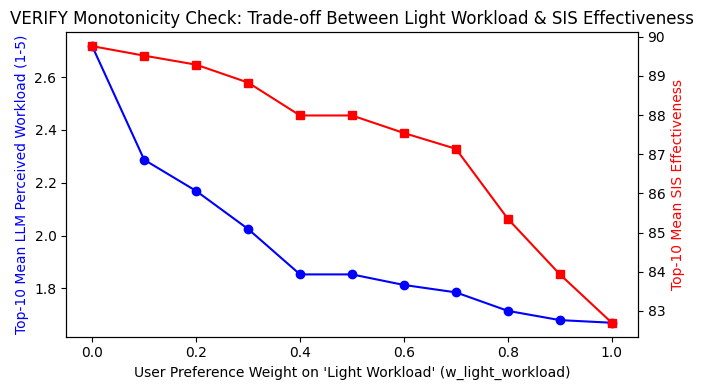

In [5]:
# ---------------------------------------------------------
# PART C: VERIFY Framework Validation (Active 2026-27 Courses)
# ---------------------------------------------------------
grid_weights = np.linspace(0.0, 1.0, 11)
avg_workloads = []
avg_sis = []

for w in grid_weights:
    top10_w = recommend_courses(df_active, w_quality=1-w, w_sentiment=0.0, w_light_workload=w, w_reg_ease=0.0, top_k=10)
    avg_workloads.append(top10_w["llm_perceived_workload"].mean())
    avg_sis.append(top10_w["sis_mean_effectiveness"].mean())

fig, ax1 = plt.subplots(figsize=(7, 4))
ax2 = ax1.twinx()
ax1.plot(grid_weights, avg_workloads, 'b-o', label="Mean Perceived Workload (Lower = Chiller)")
ax2.plot(grid_weights, avg_sis, 'r-s', label="Mean SIS Effectiveness (Higher = Better)")
ax1.set_xlabel("User Preference Weight on 'Light Workload' (w_light_workload)")
ax1.set_ylabel("Top-10 Mean LLM Perceived Workload (1-5)", color='b')
ax2.set_ylabel("Top-10 Mean SIS Effectiveness", color='r')
plt.title("VERIFY Monotonicity Check: Trade-off Between Light Workload & SIS Effectiveness")
plt.tight_layout()
plt.savefig("verify_recommendation_sensitivity.png", dpi=300)
plt.show()